# Part 2: ICA 

In this notebook, we apply ICA to fMRI data to identify spatial patterns of brain activity in a data-driven manner, without using GLM. We then compare the resulting components with the GLM results to investigate overlapping brain regions.

Loading libraries and data preparation 

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from sklearn.decomposition import FastICA 
from nilearn.plotting import plot_stat_map

from nilearn import datasets
from nilearn.image import resample_to_img
from nilearn.maskers import NiftiMasker
from nilearn.plotting import plot_roi
from scipy.stats import zscore

%matplotlib inline

In [2]:
project_dir = Path.cwd()


#Load the motion-corrected and smoothed functional image
fmri_path = project_dir / "dataset/derivatives/func/tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz"

img = nib.load(str(fmri_path))

print("Image dimensions:", img.shape)
print("Number of timepoints:", img.shape[-1])
print(img.affine)

Image dimensions: (91, 109, 91, 311)
Number of timepoints: 311
[[  -2.    0.    0.   90.]
 [   0.    2.    0. -126.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]]


## Q1: Apply ICA on the subject fMRI runs, considering one timepoint as one sample.

### Step 1: Brain Masking and Data Preparation 

In this section, we prepare the fMRI data for ICA by: 
1. Loading a standard brain mask and resampling it to match the voxel grid of our functional MRI image using its spatial dimensions and affine matrix
2. Extracting the brain voxel signals by converting the 4D fMRI data  (91, 109, 91, 311) into a 2D matrix (311, 235818), where the rows represent time points and columns represent brain voxels.
3. Normalizing the data using z-scores


X matrix shape: (311, 235818)


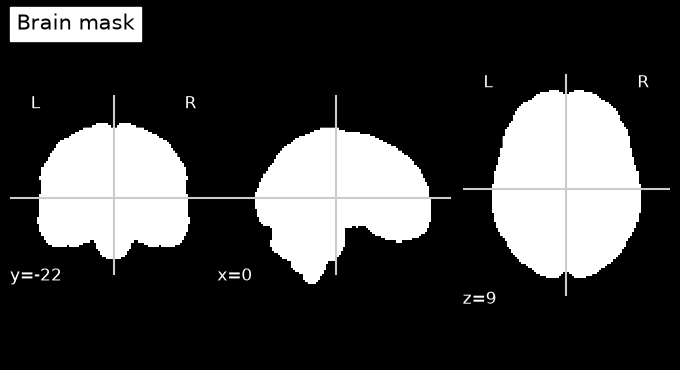

In [3]:
#spatial dimensions and affine matrix of our fmri volume
affine = img.affine
x, y, z, n_volumes = img.shape


icbms = datasets.fetch_icbm152_2009() #standard mask

ref_img = nib.Nifti1Image(np.zeros((x, y, z)), affine)

#resampling the mask to match our fmri
mask_img = resample_to_img(icbms.mask, ref_img, interpolation="nearest")

plot_stat_map(mask_img, black_bg=True, title="Brain mask", colorbar=False) 

# Masked voxel signals: X = (time points, brain voxels)
masker = NiftiMasker(mask_img=mask_img)
X = masker.fit_transform(img) #2D matrix

# Normalize 
X = zscore(X, axis=0)
X = np.nan_to_num(X, 0)

print("X matrix shape:", X.shape) #each timepoint is one sample

### Step 2: Applying ICA 

We apply ICA considering one timepoint as one sample. We estimate 10 statistically independent components as an initial starting point.

In [4]:
# number of components 
n = 10 # we also tried 5 and 15 

ica = FastICA(n_components=n, random_state=0, max_iter=1000)

S_ = ica.fit_transform(X)

print("ICA sources:", S_.shape)

ICA sources: (311, 10)


## Q2: Select number of components with justification. 

Displaying the spatial map of each selected component: 
Where in the brain does each ICA component have strong weights? 

- When we applied ICA with time points as samples, our output turned out to be (311, 10) 
We only get 311 vallues that tell us how component 1 changes over time. 
- But to plot a spatial brain map, we need to know how strongly each of the 235,818 voxels contributes to that component. 
- We know how the 10 ICA components relate the original 235,818 voxels my the mixing matrix.

We have the voxel values needed to plot the 10 spatial maps. 

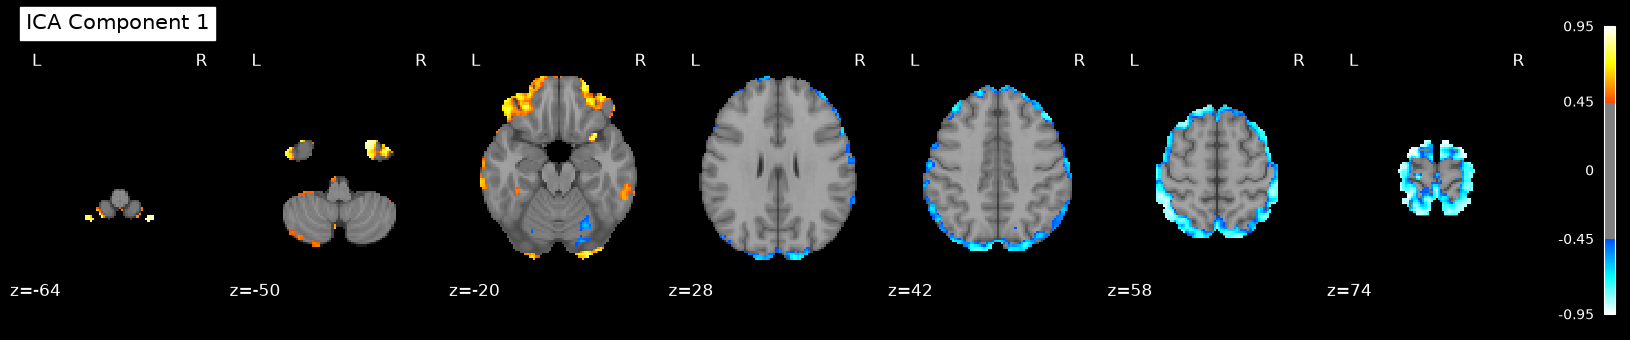

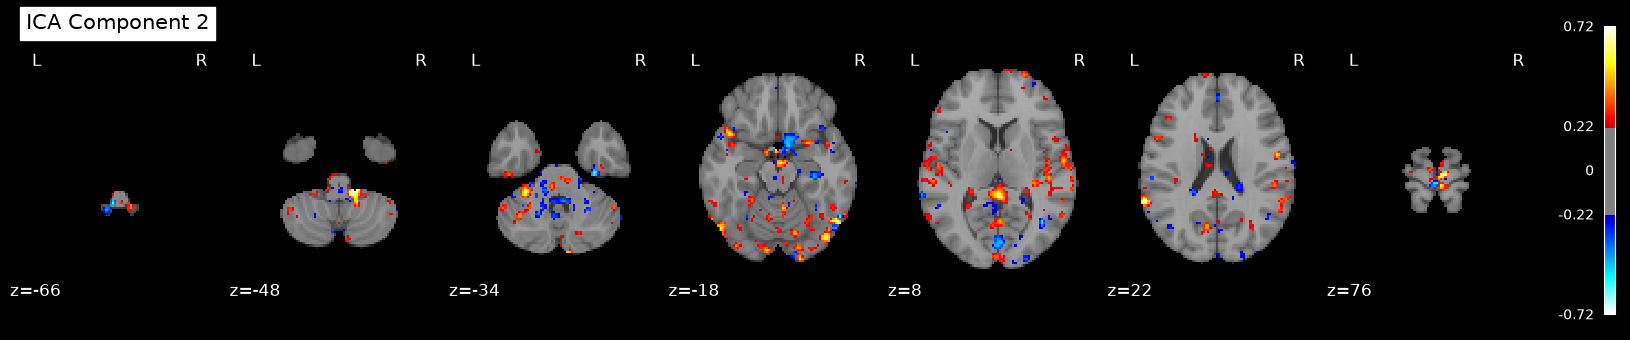

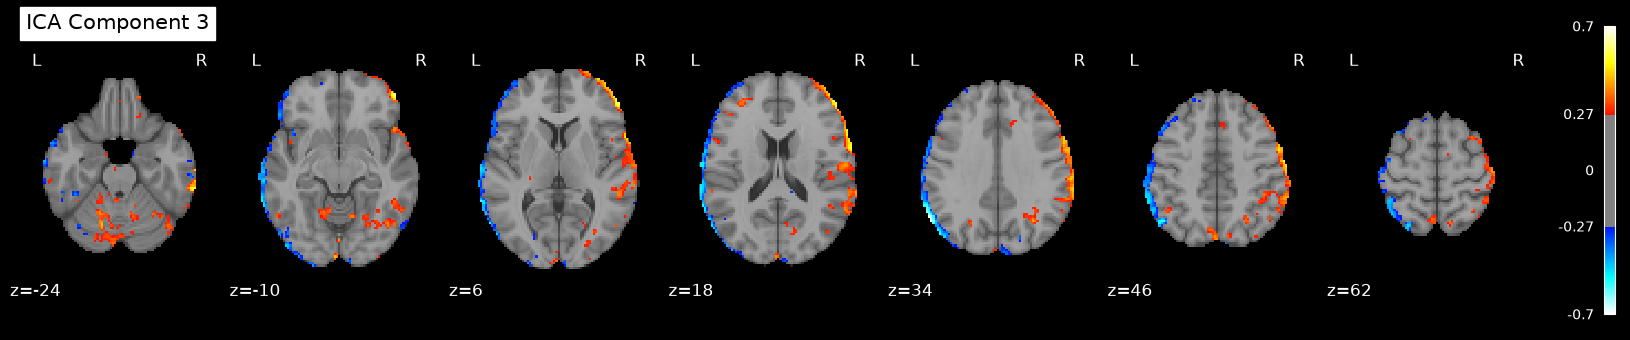

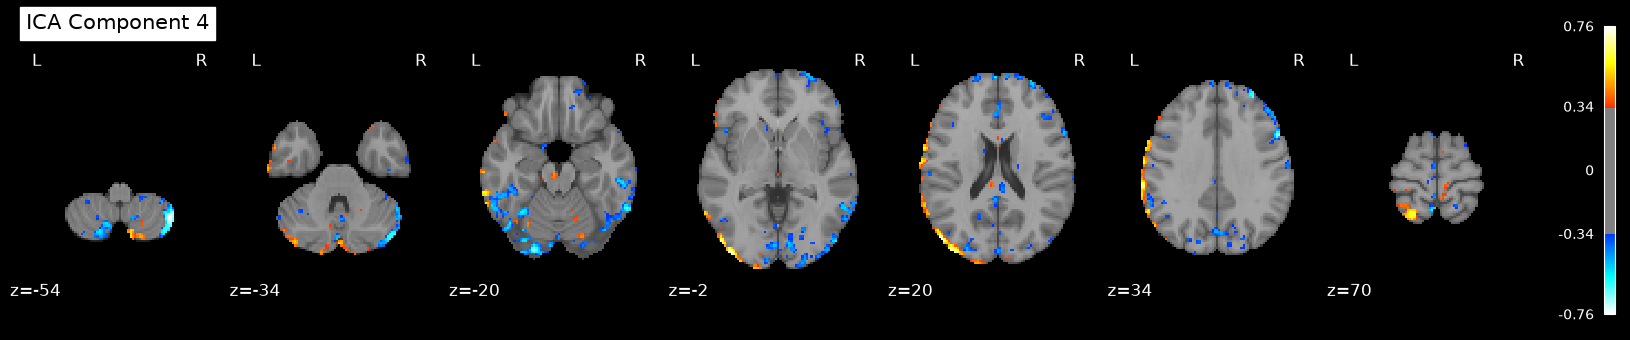

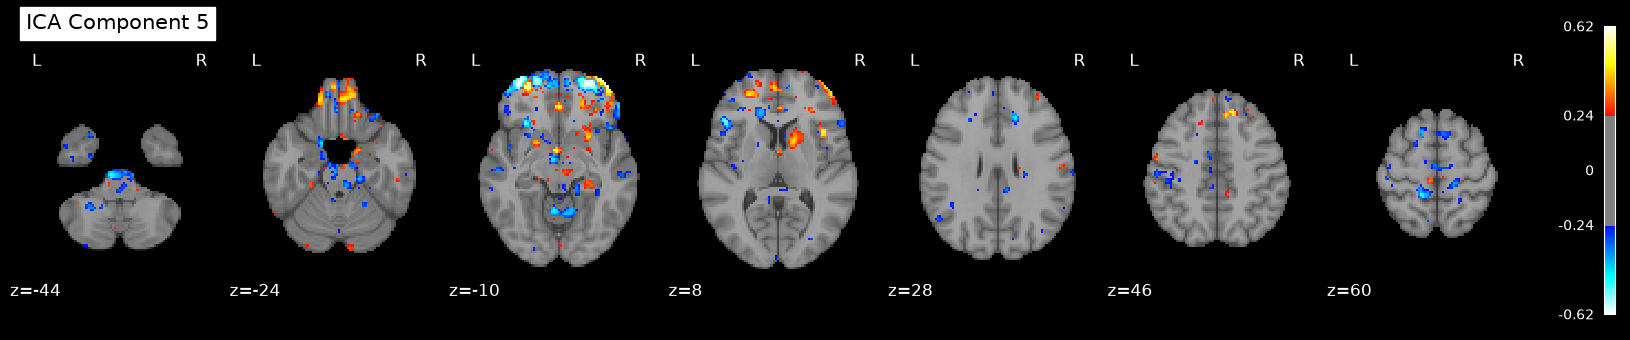

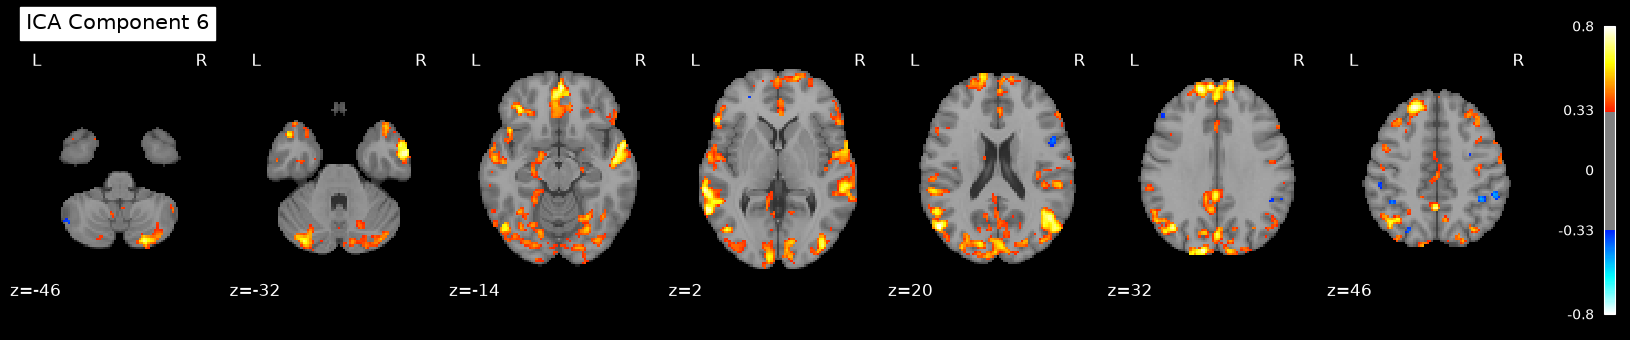

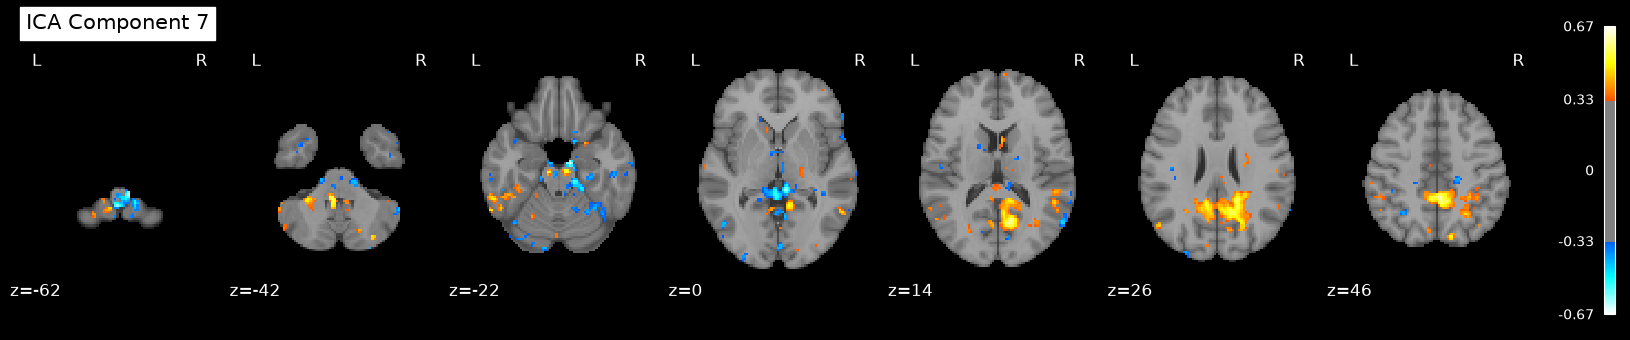

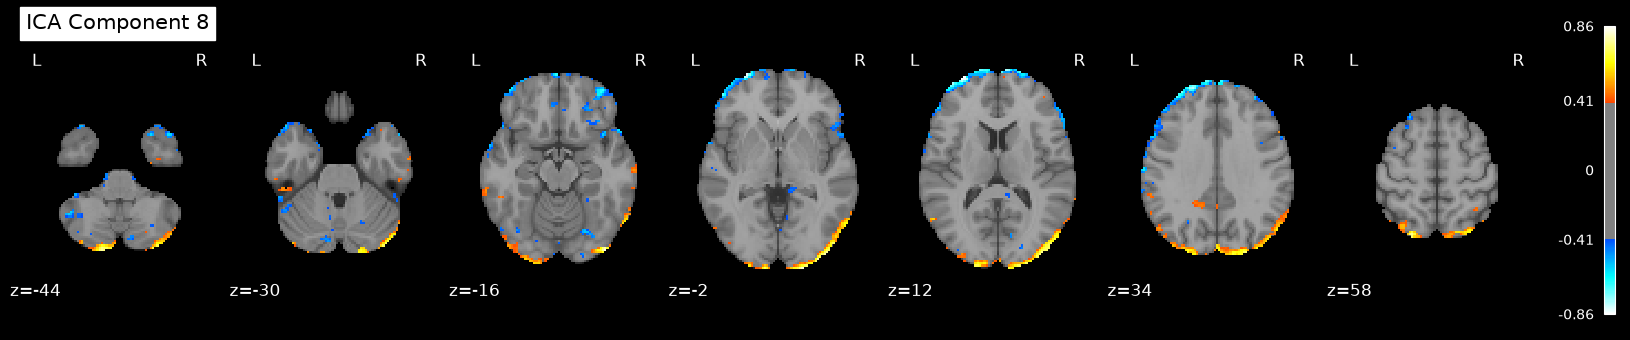

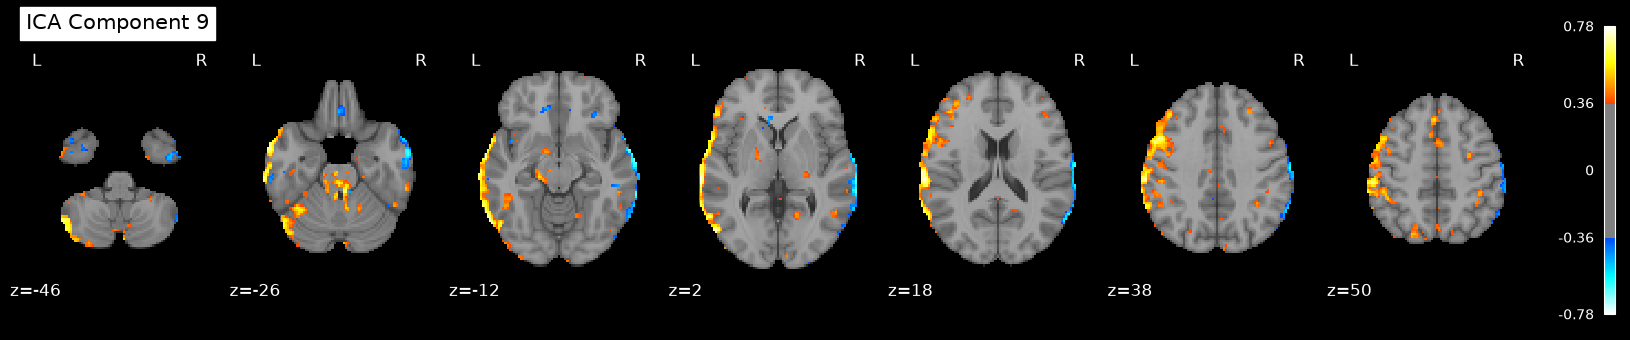

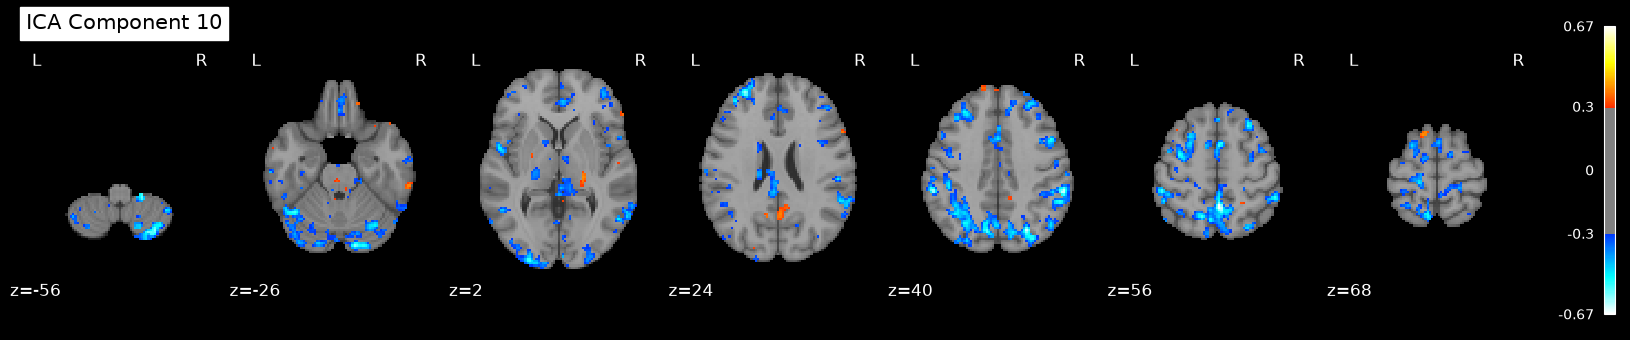

In [5]:
# Create the output folder if it does not exist
ica_figures_path = project_dir / "report_images" / "ICA"
ica_figures_path.mkdir(parents=True, exist_ok=True)

# Spatial maps from ICA
spatial_maps = ica.mixing_.T

# Plot and save each component
for idx in range(n):
    s = spatial_maps[idx, :]
    s_img = masker.inverse_transform(s)

    display = plot_stat_map(
        s_img,
        display_mode="z",
        title=f"ICA Component {idx + 1}",
        colorbar=True,
        black_bg=True,
        threshold=2 * np.std(s)
    )

    display.savefig(
        str(ica_figures_path / f"ICA_{idx + 1:02d}.png"),
        dpi=300
    )

    plt.show()

### Choice of number of components and interpretation: 

We varied the number of independent components in the preceding cell and tested out 5, 10, and 15 components. For each of these tests, we visualized the spatial map of every component in axial view and compared the resulting patters. We chose 10 components as a compromise between spatial detail and clarity. 10 components gave us more seperation than 5, while 15 provided us with additional detail without an obvious improvement in interpretation. 

For example, with 10 components, component 5 showed a prominent frontal pattern, while component 1 showed a broader pattern along the outer brain boundary.

## Q3: Correlation between Timecourses

Timecourses shape: (311, 10)


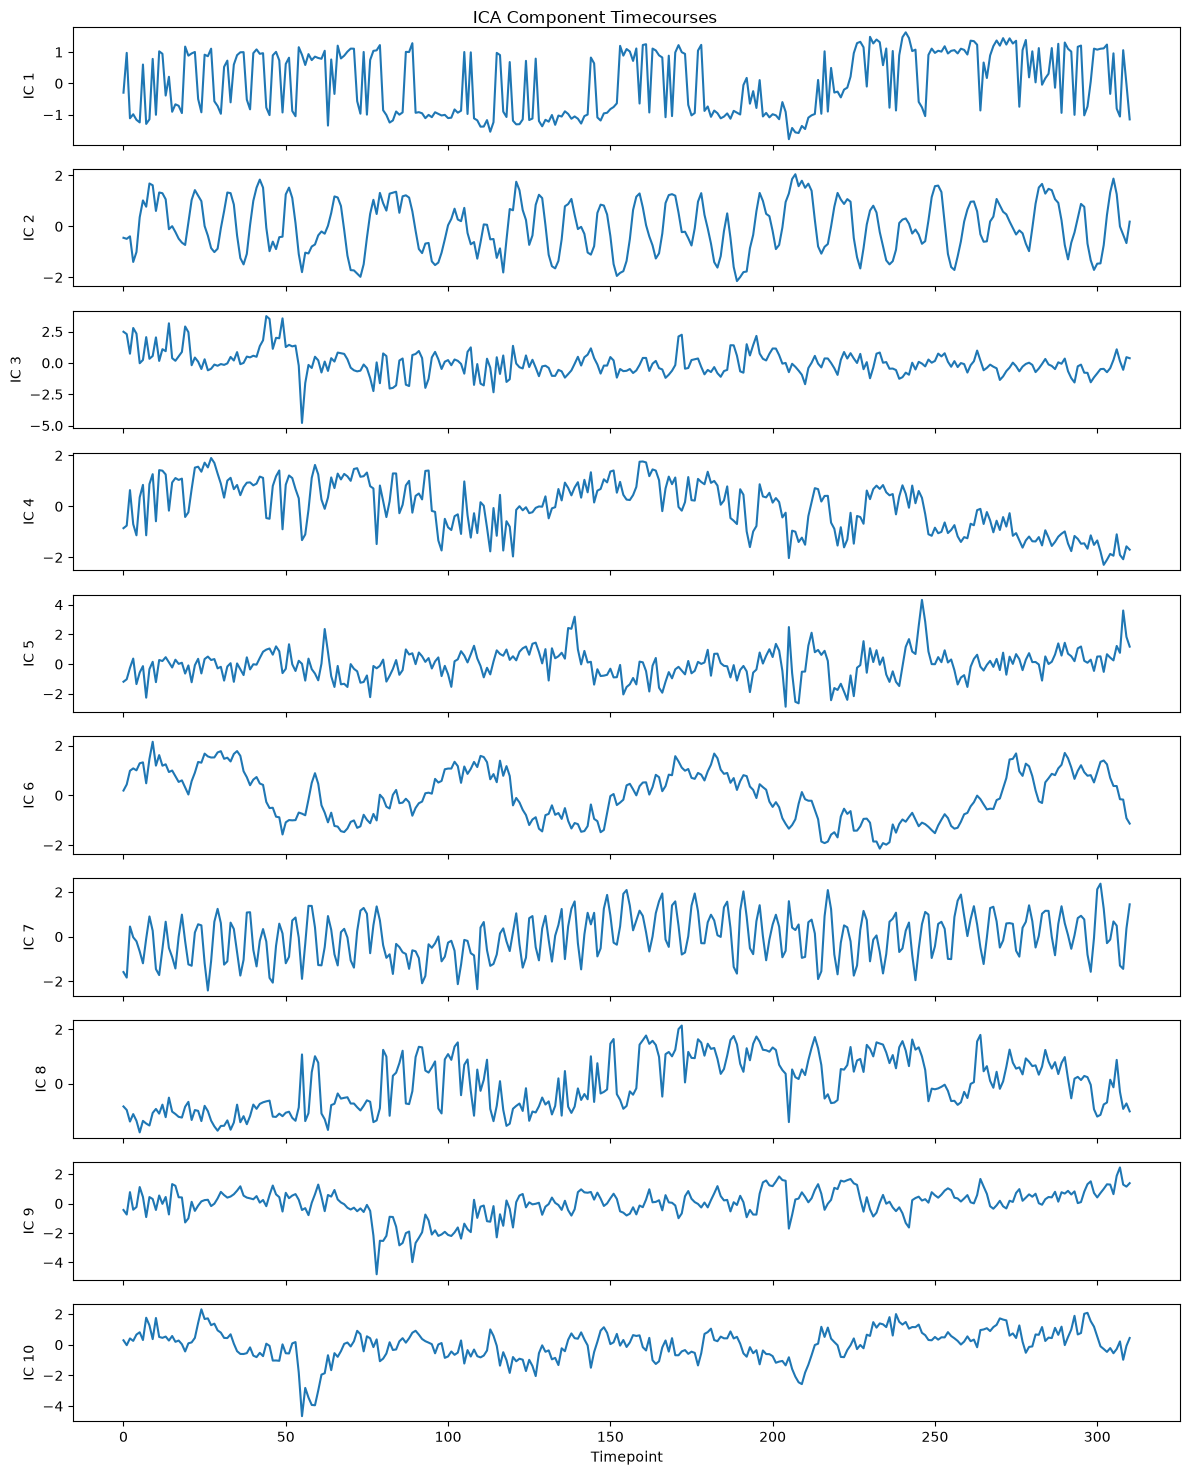

In [6]:
# Timecourses of the 10 ICA components
timecourses = S_
print('Timecourses shape:', timecourses.shape)

fig, axes = plt.subplots(n, 1, figsize=(12, 15), sharex=True)
for i in range(n):
    axes[i].plot(timecourses[:, i])
    axes[i].set_ylabel(f'IC {i + 1}')

axes[-1].set_xlabel('Timepoint')
fig.suptitle('ICA Component Timecourses')
plt.tight_layout()
plt.show()

In [7]:
# Load the Part 1 GLM regressors for the same functional run
design_matrix = pd.read_csv(project_dir / 'glm_design_matrix.csv')

print('GLM matrix:', design_matrix.shape)
print('ICA time courses:', timecourses.shape)
print('Regressors:', design_matrix.columns.tolist())


GLM matrix: (311, 13)
ICA time courses: (311, 10)
Regressors: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


## Correlation Matrix

In [8]:
# Arrange the ICA time courses and GLM regressors by time point
component_names = [f'IC {i + 1}' for i in range(n)]
ica_df = pd.DataFrame(timecourses[:, :10], columns=component_names)
regressors = design_matrix.drop(columns=['constant'])

# Compute ICA-to-regressor Pearson correlations
combined = pd.concat([ica_df, regressors], axis=1)
corr_matrix = combined.corr().loc[component_names, regressors.columns]

print(corr_matrix.round(2))

       math  story  rot_x  rot_y  rot_z  trans_x  trans_y  trans_z  drift_1  \
IC 1  -0.03   0.02   0.17   0.31   0.02     0.26     0.29    -0.97    -0.19   
IC 2  -0.03   0.01   0.01   0.10  -0.11     0.11     0.06    -0.04    -0.02   
IC 3  -0.02  -0.03  -0.15  -0.34   0.20    -0.49     0.09    -0.01     0.23   
IC 4   0.07  -0.04  -0.34  -0.11   0.47     0.31    -0.14    -0.04     0.53   
IC 5   0.04  -0.05  -0.05  -0.02  -0.09     0.11    -0.03     0.06    -0.12   
IC 6  -0.82   0.81   0.03  -0.25  -0.03    -0.19    -0.10     0.00     0.19   
IC 7   0.06  -0.06   0.08   0.18  -0.18     0.21    -0.01     0.04    -0.26   
IC 8  -0.08   0.10   0.65   0.09  -0.15    -0.12    -0.86     0.14    -0.52   
IC 9   0.23  -0.22   0.14   0.54  -0.23     0.65     0.11    -0.03    -0.35   
IC 10 -0.27   0.29  -0.02   0.11  -0.06     0.03     0.14     0.08    -0.26   

       drift_2  drift_3  drift_4  
IC 1      0.35     0.01    -0.09  
IC 2      0.10     0.06     0.00  
IC 3      0.18     0.30  

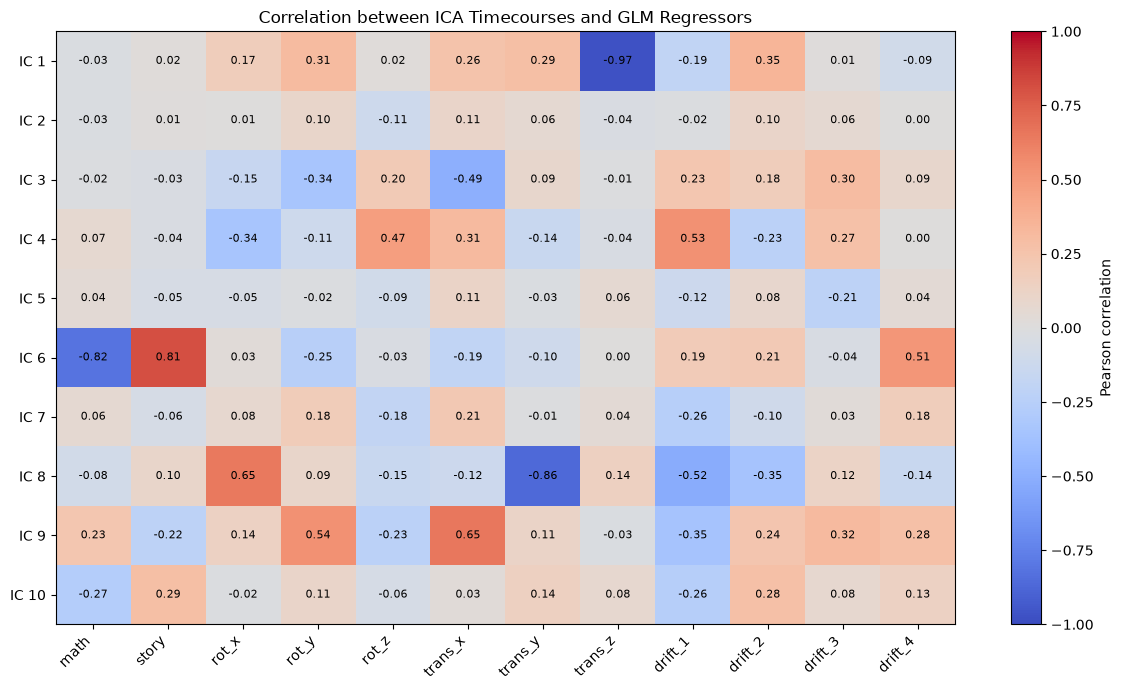

In [9]:
# Visualize correlation matrix 
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')

ax.set_xticks(np.arange(len(regressors.columns)))
ax.set_xticklabels(regressors.columns, rotation=45, ha='right')
ax.set_yticks(np.arange(n))
ax.set_yticklabels(component_names)

for i in range(n):
    for j in range(len(regressors.columns)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                ha='center', va='center', fontsize=8)

fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Correlation between ICA Timecourses and GLM Regressors')
plt.tight_layout()

# Save the correlation matrix
fig.savefig(
    str(ica_figures_path / f"ICA_correlation_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Comments: 

The correlation matrix shows that IC 6 is strongly associated with the experimental tasks, correlating negatively with math (r = −0.82) and positively with story (r = 0.81). Its spatial map contains distributed cortical regions, although its precise functional interpretation remains uncertain. IC 1 is strongly correlated with Z-axis translation (r = −0.97), consistent with the boundary-related pattern in its spatial map and suggesting motion artifacts. IC 8 also shows strong associations with motion, correlating with Y-axis translation (r = −0.86) and X-axis rotation (r = 0.65).

Correlations with individual drift regressors are moderate at most, with the largest absolute value being 0.53. These associations do not clearly identify a drift-dominated component. Most remaining components show weak correlations with the task regressors, although some have moderate associations with motion.

Overall, ICA identified a component strongly related to the math and story tasks, as well as components associated with head motion. However, the task correlations alone do not establish which brain regions are specifically involved in each task.